# Lab 1 — Introduction to PyTorch: tensors and autograd

In this notebook we look at the two fundamental building blocks of PyTorch:

1. **Tensors** — multidimensional arrays (like NumPy's) that can also live on the GPU.
2. **Autograd** — the *automatic differentiation* engine that lets PyTorch compute the derivatives
   of (almost) any function written with tensors. This is what makes training neural networks possible.

**How to use this notebook:** run the cells one at a time (`Shift + Enter`), read the explanation before
each cell, and try to *predict* the output before running it.

**Contents**
1. Setup
2. What is a tensor
3. Creating tensors
4. Attributes: `shape`, `dtype`, `device`
5. Indexing, slicing and boolean masks
6. Changing shape: `reshape`, `view`, `unsqueeze`, `permute`
7. Combining tensors: `cat` and `stack`
8. Arithmetic operations
9. Broadcasting
10. Aggregations and single-element tensors
11. In-place operations
12. The bridge to NumPy
13. Autograd: PyTorch computes derivatives
14. From derivatives to optimization: gradient descent
15. Exercises

## 1. Setup

Import the libraries we will use. If PyTorch is not installed, uncomment the `pip install` line
(it is already available on Colab).

In [1]:
# !pip install torch numpy matplotlib

import math

import matplotlib.pyplot as plt
import numpy as np
import torch

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA GPU available: {torch.cuda.is_available()}")

# Fix the seed so the "random" numbers are the same on every run
torch.manual_seed(0)

PyTorch version: 2.6.0
CUDA GPU available: True


## 2. What is a tensor

A **tensor** is simply an array of numbers with an arbitrary number of dimensions (*axes*):

| Dimensions (`ndim`) | Common name | Deep learning example |
|---|---|---|
| 0 | scalar | the value of the loss |
| 1 | vector | the biases of a layer |
| 2 | matrix | the weights of a linear layer, a batch of vectors |
| 3 | 3D tensor | a color image (channels × height × width) |
| 4 | 4D tensor | a batch of images (batch × channels × H × W) |

In [2]:
scalar = torch.tensor(3.14)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1, 2], [3, 4]])
image = torch.rand(3, 32, 32)           # 3 RGB channels, 32x32 pixels
image_batch = torch.rand(16, 3, 32, 32)  # 16 images

for name, t in [("scalar", scalar), ("vector", vector), ("matrix", matrix),
                ("image", image), ("image_batch", image_batch)]:
    print(f"{name:12s} ndim={t.ndim}  shape={tuple(t.shape)}")

scalar       ndim=0  shape=()
vector       ndim=1  shape=(3,)
matrix       ndim=2  shape=(2, 2)
image        ndim=3  shape=(3, 32, 32)
image_batch  ndim=4  shape=(16, 3, 32, 32)


## 3. Creating tensors

### 3.1 From Python data (lists)
`torch.tensor` creates a tensor by copying the data. The type (`dtype`) is inferred automatically.

In [3]:
data = [[1, 2], [3, 4]]
x_data = torch.tensor(data)
print(x_data)
print(x_data.dtype)   # integers -> torch.int64

tensor([[1, 2],
        [3, 4]])
torch.int64


### 3.2 From NumPy arrays

In [4]:
np_array = np.array(data)
x_np = torch.from_numpy(np_array)
print(x_np)

tensor([[1, 2],
        [3, 4]])


### 3.3 From other tensors
The `*_like` functions create a new tensor with the **same shape** (and, by default, the same `dtype`)
as an existing tensor.

In [5]:
x_ones = torch.ones_like(x_data)
print(f"Ones:\n{x_ones}\n")

x_rand = torch.rand_like(x_data, dtype=torch.float)  # override the dtype
print(f"Random:\n{x_rand}")

Ones:
tensor([[1, 1],
        [1, 1]])

Random:
tensor([[0.6799, 0.3132],
        [0.4058, 0.2807]])


⚠️ **Watch out:** why did we have to specify `dtype=torch.float` above?
Because `x_data` contains integers, and it makes no sense to draw uniform random numbers in $[0, 1)$ as integers.
Let's see the error:

In [6]:
try:
    torch.rand_like(x_data)
except RuntimeError as e:
    print("Error:", e)

Error: "check_uniform_bounds" not implemented for 'Long'


### 3.4 From a shape
Often we just want a tensor of a given shape, filled with constant or random values.

In [7]:
shape = (2, 3)
print(f"rand  (uniform in [0,1)):\n{torch.rand(shape)}\n")
print(f"randn (normal N(0,1)):\n{torch.randn(shape)}\n")
print(f"ones:\n{torch.ones(shape)}\n")
print(f"zeros:\n{torch.zeros(shape)}\n")
print(f"full (constant value):\n{torch.full(shape, 7.0)}")

rand  (uniform in [0,1)):
tensor([[0.5183, 0.6860, 0.9883],
        [0.8769, 0.5698, 0.7947]])

randn (normal N(0,1)):
tensor([[ 0.8257,  0.2734, -1.8494],
        [-1.5851,  1.3980,  0.6808]])

ones:
tensor([[1., 1., 1.],
        [1., 1., 1.]])

zeros:
tensor([[0., 0., 0.],
        [0., 0., 0.]])

full (constant value):
tensor([[7., 7., 7.],
        [7., 7., 7.]])


### 3.5 Sequences and special matrices
Very handy for building axes, grids and identity matrices.

In [8]:
print("arange:  ", torch.arange(0, 10, 2))          # like Python's range()
print("linspace:", torch.linspace(0, 1, steps=5))   # 5 evenly spaced points between 0 and 1
print("eye:\n", torch.eye(3))                       # identity matrix

arange:   tensor([0, 2, 4, 6, 8])
linspace: tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])
eye:
 tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])


## 4. Tensor attributes

Every tensor has three attributes that we will check constantly while debugging:
- `shape` → its shape
- `dtype` → the data type (e.g. `float32`, `int64`)
- `device` → where it lives in memory (`cpu`, `cuda`, `mps`)

> 💡 Most errors in PyTorch are caused by mismatched *shape*, *dtype* or *device*!

In [9]:
tensor = torch.rand(3, 4)

print(f"Shape:    {tensor.shape}")
print(f"Datatype: {tensor.dtype}")
print(f"Device:   {tensor.device}")

Shape:    torch.Size([3, 4])
Datatype: torch.float32
Device:   cpu


### 4.1 Changing dtype
Neural networks almost always work in `float32`. Classification labels, on the other hand, are `int64` (`long`).

In [10]:
t_int = torch.tensor([1, 2, 3])
t_float = t_int.float()          # equivalent to t_int.to(torch.float32)
print(t_int.dtype, "->", t_float.dtype)

# Operations between different dtypes: PyTorch "promotes" to the more general type
print((t_int + t_float).dtype)

torch.int64 -> torch.float32
torch.float32


### 4.2 Moving tensors to the GPU
By default tensors are created on the CPU. If a GPU is available we move them with `.to(device)`.
It is good practice to define a `device` variable at the beginning and use it everywhere: this way the
same code runs on both CPU and GPU.

In [11]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():   # GPU on Apple Silicon Macs
    device = "mps"
else:
    device = "cpu"
print(f"Using device: {device}")

tensor = tensor.to(device)
print(f"The tensor is now on: {tensor.device}")

Using device: cuda
The tensor is now on: cuda:0


⚠️ Two tensors must be on the **same device** to be combined.
(If you are only using the CPU this cell will not raise an error: try it on Colab with a GPU!)

In [12]:
a = torch.ones(3)                  # on CPU
b = torch.ones(3).to(device)       # on `device`
try:
    print(a + b)
except RuntimeError as e:
    print("Error:", e)

Error: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu!


## 5. Indexing, slicing and boolean masks

The syntax is the same as NumPy: `tensor[rows, columns]`.

In [13]:
tensor = torch.arange(16).reshape(4, 4)
print(tensor, "\n")
print(f"First row:     {tensor[0]}")
print(f"First column:  {tensor[:, 0]}")
print(f"Last column:   {tensor[..., -1]}")   # '...' = "all the preceding dimensions"
print(f"Central submatrix:\n{tensor[1:3, 1:3]}")

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11],
        [12, 13, 14, 15]]) 

First row:     tensor([0, 1, 2, 3])
First column:  tensor([ 0,  4,  8, 12])
Last column:   tensor([ 3,  7, 11, 15])
Central submatrix:
tensor([[ 5,  6],
        [ 9, 10]])


We can also **assign** values through slicing:

In [14]:
tensor = torch.ones(4, 4)
tensor[:, 1] = 0
print(tensor)

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


### 5.1 Boolean masks
An element-wise comparison returns a tensor of booleans, which we can use to select or modify elements.
Here, for example, we implement a ReLU "by hand": $\max(0, x)$.

In [15]:
x = torch.randn(8)
print("x:    ", x)
mask = x > 0
print("mask: ", mask)
print("positives only:", x[mask])

x_relu = x.clone()
x_relu[x_relu < 0] = 0
print("ReLU(x):", x_relu)
print("Same as torch.relu?", torch.equal(x_relu, torch.relu(x)))

x:     tensor([ 0.6269,  0.4029,  0.9916,  0.0413,  2.2368,  0.4927,  1.0236, -0.4712])
mask:  tensor([ True,  True,  True,  True,  True,  True,  True, False])
positives only: tensor([0.6269, 0.4029, 0.9916, 0.0413, 2.2368, 0.4927, 1.0236])
ReLU(x): tensor([0.6269, 0.4029, 0.9916, 0.0413, 2.2368, 0.4927, 1.0236, 0.0000])
Same as torch.relu? True


## 6. Changing shape

Changing the shape of a tensor (without changing its data) happens all the time in deep learning:
for example to "flatten" an image before a linear layer, or to add the batch dimension.

In [16]:
x = torch.arange(12)
print("Original:", x.shape)

print("reshape(3, 4):\n", x.reshape(3, 4))
print("reshape(2, -1):\n", x.reshape(2, -1))   # -1 = "infer this dimension for me"

Original: torch.Size([12])
reshape(3, 4):
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
reshape(2, -1):
 tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11]])


### `unsqueeze` / `squeeze`
Add / remove dimensions of size 1. Typical use: turning a single example into a batch of size 1.

In [17]:
img = torch.rand(3, 32, 32)
batch = img.unsqueeze(0)
print("img:           ", img.shape)
print("unsqueeze(0):  ", batch.shape)
print("squeeze():     ", batch.squeeze().shape)

img:            torch.Size([3, 32, 32])
unsqueeze(0):   torch.Size([1, 3, 32, 32])
squeeze():      torch.Size([3, 32, 32])


### `permute` / `transpose`
Reorder the axes. Classic example: image libraries (PIL, matplotlib) use the $H \times W \times C$
layout, while PyTorch uses $C \times H \times W$.

In [18]:
img_chw = torch.rand(3, 32, 64)
img_hwc = img_chw.permute(1, 2, 0)
print("C x H x W:", img_chw.shape, " ->  H x W x C:", img_hwc.shape)

m = torch.rand(2, 5)
print("Transpose:", m.shape, "->", m.T.shape)

C x H x W: torch.Size([3, 32, 64])  ->  H x W x C: torch.Size([32, 64, 3])
Transpose: torch.Size([2, 5]) -> torch.Size([5, 2])


## 7. Combining tensors

- `torch.cat` **concatenates** along an existing dimension.
- `torch.stack` **stacks** by creating a new dimension.

In [19]:
tensor = torch.ones(2, 3)
print("cat dim=0:", torch.cat([tensor, tensor, tensor], dim=0).shape)
print("cat dim=1:", torch.cat([tensor, tensor, tensor], dim=1).shape)
print("stack    :", torch.stack([tensor, tensor, tensor]).shape)

cat dim=0: torch.Size([6, 3])
cat dim=1: torch.Size([2, 9])
stack    : torch.Size([3, 2, 3])


## 8. Arithmetic operations

⚠️ A **fundamental** distinction:
- `*` is the **element-wise** product (Hadamard product)
- `@` is the **matrix** product (rows × columns)

In [20]:
A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[10., 20.], [30., 40.]])

print("Element-wise    A * B:\n", A * B)
print("Matrix product  A @ B:\n", A @ B)

Element-wise    A * B:
 tensor([[ 10.,  40.],
        [ 90., 160.]])
Matrix product  A @ B:
 tensor([[ 70., 100.],
        [150., 220.]])


There are several equivalent syntaxes for the same operation:

In [21]:
y1 = A @ A.T
y2 = A.matmul(A.T)
y3 = torch.matmul(A, A.T)

z1 = A * A
z2 = A.mul(A)
z3 = torch.mul(A, A)

print("matmul equivalent:", torch.equal(y1, y2) and torch.equal(y2, y3))
print("mul equivalent:   ", torch.equal(z1, z2) and torch.equal(z2, z3))

matmul equivalent: True
mul equivalent:    True


The matrix product requires compatible shapes: $(n \times k) @ (k \times m) \rightarrow (n \times m)$.

In [22]:
X = torch.rand(5, 3)   # 5 examples, 3 features
W = torch.rand(3, 2)   # linear layer: 3 inputs -> 2 outputs
print("X @ W:", (X @ W).shape)

try:
    W @ X
except RuntimeError as e:
    print("Error:", e)

X @ W: torch.Size([5, 2])
Error: mat1 and mat2 shapes cannot be multiplied (3x2 and 5x3)


Of course, all the element-wise math functions are available:

In [23]:
x = torch.linspace(0, 1, 5)
print("exp: ", torch.exp(x))
print("sin: ", torch.sin(x))
print("x^2: ", x ** 2)

exp:  tensor([1.0000, 1.2840, 1.6487, 2.1170, 2.7183])
sin:  tensor([0.0000, 0.2474, 0.4794, 0.6816, 0.8415])
x^2:  tensor([0.0000, 0.0625, 0.2500, 0.5625, 1.0000])


## 9. Broadcasting

When we operate on tensors of different shapes, PyTorch automatically "expands" the size-1 dimensions
(without copying data) to make them compatible. This is what happens when we add the **bias** in a linear layer:
$y = XW + b$, where $XW$ is $(N \times 2)$ and $b$ is a vector of size $2$.

Rule: comparing the shapes **from the right**, two dimensions are compatible if they are equal or if one of them is 1.

In [24]:
XW = torch.zeros(4, 2)
b = torch.tensor([1., 2.])
print("(4,2) + (2,) ->\n", XW + b)

col = torch.tensor([[10.], [20.], [30.]])   # shape (3, 1)
row = torch.tensor([1., 2., 3., 4.])        # shape (4,)
print("\n(3,1) + (4,) ->\n", col + row)     # result (3, 4)

(4,2) + (2,) ->
 tensor([[1., 2.],
        [1., 2.],
        [1., 2.],
        [1., 2.]])

(3,1) + (4,) ->
 tensor([[11., 12., 13., 14.],
        [21., 22., 23., 24.],
        [31., 32., 33., 34.]])


## 10. Aggregations and single-element tensors

Aggregation functions (`sum`, `mean`, `max`, ...) can act on the whole tensor or along a dimension `dim`.

In [25]:
t = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.]])
print("total sum:      ", t.sum())
print("sum along dim=0:", t.sum(dim=0))   # sum over rows    -> one per column
print("sum along dim=1:", t.sum(dim=1))   # sum over columns -> one per row
print("mean:           ", t.mean())
print("max per row:    ", t.max(dim=1).values)
print("argmax per row: ", t.argmax(dim=1))   # e.g. the class predicted by a classifier

total sum:       tensor(21.)
sum along dim=0: tensor([5., 7., 9.])
sum along dim=1: tensor([ 6., 15.])
mean:            tensor(3.5000)
max per row:     tensor([3., 6.])
argmax per row:  tensor([2, 2])


The result of a full aggregation is a tensor with a single element. To get a plain Python number
we use `.item()` (we will use it, for example, to print the value of the loss).

In [26]:
agg = t.sum()
agg_item = agg.item()
print(agg, type(agg))
print(agg_item, type(agg_item))

tensor(21.) <class 'torch.Tensor'>
21.0 <class 'float'>


## 11. In-place operations

Operations ending with `_` (e.g. `add_`, `mul_`, `zero_`) modify the tensor **directly**,
without creating a new one.

In [27]:
tensor = torch.ones(2, 3)
print(tensor, "\n")
tensor.add_(5)
print(tensor)

tensor([[1., 1., 1.],
        [1., 1., 1.]]) 

tensor([[6., 6., 6.],
        [6., 6., 6.]])


They save memory, but must be used with care: they overwrite values that autograd might need
to compute derivatives (we will see this in section 13). In general: **avoid them** unless
you know what you are doing.

## 12. The bridge to NumPy

Tensors (on CPU) and NumPy arrays can **share the same memory**: changing one also changes the other!

In [28]:
# Tensor -> NumPy
t = torch.ones(5)
n = t.numpy()
print(f"t: {t}\nn: {n}\n")

t.add_(1)
print("After t.add_(1):")
print(f"t: {t}\nn: {n}")

t: tensor([1., 1., 1., 1., 1.])
n: [1. 1. 1. 1. 1.]

After t.add_(1):
t: tensor([2., 2., 2., 2., 2.])
n: [2. 2. 2. 2. 2.]


In [29]:
# NumPy -> Tensor
n = np.ones(5)
t = torch.from_numpy(n)

np.add(n, 1, out=n)
print("After np.add(n, 1, out=n):")
print(f"t: {t}\nn: {n}")

After np.add(n, 1, out=n):
t: tensor([2., 2., 2., 2., 2.], dtype=torch.float64)
n: [2. 2. 2. 2. 2.]


If we want an independent copy we use `torch.tensor(n)` (copies) instead of `torch.from_numpy(n)`,
or `t.clone()`.

In [30]:
n = np.ones(3)
t_copy = torch.tensor(n)
n += 100
print("n:     ", n)
print("t_copy:", t_copy, "(unchanged)")

n:      [101. 101. 101.]
t_copy: tensor([1., 1., 1.], dtype=torch.float64) (unchanged)


---
## 13. Autograd: PyTorch computes derivatives

Training a neural network means minimizing a *loss* $L(\theta)$ with respect to the parameters $\theta$.
To do that we need the **gradient** $\nabla_\theta L$, i.e. the partial derivatives of the loss with respect to each parameter.

PyTorch computes it **automatically**:
1. we mark the tensors we want to differentiate with respect to using `requires_grad=True`;
2. during the computation (*forward pass*), PyTorch records every operation in a **computational graph**;
3. calling `.backward()` on the result, PyTorch walks the graph backwards applying the
   **chain rule** (*backpropagation*);
4. the derivatives are stored in the `.grad` attribute of the starting tensors.

### 13.1 First example: $f(x) = x^2$

We know that $f'(x) = 2x$, so at $x = 3$ we expect $f'(3) = 6$.

In [31]:
x = torch.tensor(3.0, requires_grad=True)
y = x ** 2

print("y =", y)       # note grad_fn: y "remembers" which operation produced it
y.backward()          # computes dy/dx
print("dy/dx at x=3:", x.grad)

y = tensor(9., grad_fn=<PowBackward0>)
dy/dx at x=3: tensor(6.)


### 13.2 A slightly richer function: a polynomial

$f(x) = 3x^3 - 2x^2 + 5x - 1 \quad\Rightarrow\quad f'(x) = 9x^2 - 4x + 5$

At $x = 2$: $f'(2) = 36 - 8 + 5 = 33$.

In [32]:
x = torch.tensor(2.0, requires_grad=True)
f = 3 * x**3 - 2 * x**2 + 5 * x - 1
f.backward()

analytic_derivative = 9 * 2.0**2 - 4 * 2.0 + 5
print(f"Autograd:  f'(2) = {x.grad.item()}")
print(f"Analytic:  f'(2) = {analytic_derivative}")

Autograd:  f'(2) = 33.0
Analytic:  f'(2) = 33.0


### 13.3 The derivative of a known function over a whole interval: $\sin(x)$

We know that $\frac{d}{dx}\sin(x) = \cos(x)$. Let's verify it by computing the derivative at **200 points at once**.

💡 **Trick:** `.backward()` can only be called on a **scalar**. So we differentiate the sum
$S = \sum_i \sin(x_i)$: since each term depends only on its own $x_i$, we have
$\frac{\partial S}{\partial x_i} = \cos(x_i)$. Therefore `x.grad` will contain exactly the derivative at each point.

In [33]:
x = torch.linspace(-2 * math.pi, 2 * math.pi, 200, requires_grad=True)
y = torch.sin(x)
y.sum().backward()

autograd_derivative = x.grad
analytic_derivative = torch.cos(x)
print("Does autograd match cos(x)?", torch.allclose(autograd_derivative, analytic_derivative))

Does autograd match cos(x)? True


Let's plot the result. Note: to pass a tensor that is part of the graph to matplotlib we must first
"detach" it with `.detach()` (more on this in 13.8).

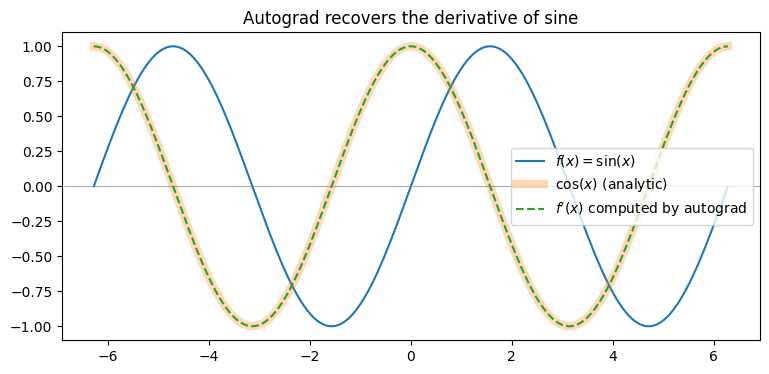

In [34]:
x_np = x.detach().numpy()

plt.figure(figsize=(9, 4))
plt.plot(x_np, y.detach().numpy(), label=r"$f(x) = \sin(x)$")
plt.plot(x_np, analytic_derivative.detach().numpy(), lw=6, alpha=0.3, label=r"$\cos(x)$ (analytic)")
plt.plot(x_np, autograd_derivative.numpy(), "--", label=r"$f'(x)$ computed by autograd")
plt.axhline(0, color="gray", lw=0.5)
plt.legend()
plt.title("Autograd recovers the derivative of sine")
plt.show()

### 13.4 A deep learning function: the sigmoid

$\sigma(x) = \dfrac{1}{1 + e^{-x}} \qquad \sigma'(x) = \sigma(x)\,\big(1 - \sigma(x)\big)$

This derivative appears in the backpropagation of every network that uses the sigmoid. Notice how the derivative
becomes almost zero for large $|x|$: this is the **vanishing gradient** problem.

Does autograd match σ(1-σ)? True


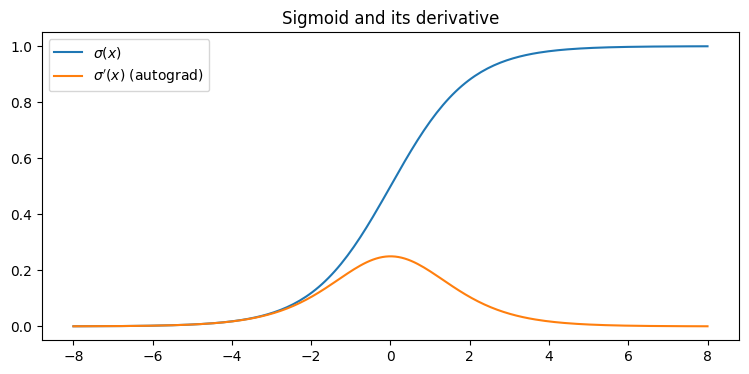

In [35]:
x = torch.linspace(-8, 8, 200, requires_grad=True)
s = torch.sigmoid(x)
s.sum().backward()

analytic = (s * (1 - s)).detach()
print("Does autograd match σ(1-σ)?", torch.allclose(x.grad, analytic))

plt.figure(figsize=(9, 4))
plt.plot(x.detach(), s.detach(), label=r"$\sigma(x)$")
plt.plot(x.detach(), x.grad, label=r"$\sigma'(x)$ (autograd)")
plt.legend()
plt.title("Sigmoid and its derivative")
plt.show()

### 13.5 The chain rule and the computational graph

Take a composite function: $f(x) = e^{\sin(x^2)}$.

By hand, with the chain rule: $f'(x) = e^{\sin(x^2)} \cdot \cos(x^2) \cdot 2x$.

PyTorch does exactly the same thing, one "link" at a time. Each intermediate tensor has a `grad_fn`
that tells which operation produced it: this is the graph that gets traversed backwards.

In [36]:
x = torch.tensor(1.5, requires_grad=True)
a = x ** 2          # a = x^2
b = torch.sin(a)    # b = sin(a)
f = torch.exp(b)    # f = exp(b)

print("grad_fn of a:", a.grad_fn)
print("grad_fn of b:", b.grad_fn)
print("grad_fn of f:", f.grad_fn)

f.backward()

x_val = 1.5
analytic = math.exp(math.sin(x_val**2)) * math.cos(x_val**2) * 2 * x_val
print(f"\nAutograd: {x.grad.item():.6f}")
print(f"Analytic: {analytic:.6f}")

grad_fn of a: <PowBackward0 object at 0x7f66cd91ff70>
grad_fn of b: <SinBackward0 object at 0x7f66cd91ff70>
grad_fn of f: <ExpBackward0 object at 0x7f66cd91ff70>

Autograd: -4.103117
Analytic: -4.103116


We can also "walk up" the graph by hand following `next_functions`, from $f$ down to $x$:

In [37]:
node = f.grad_fn
while node is not None:
    print(type(node).__name__)
    node = node.next_functions[0][0] if node.next_functions else None

ExpBackward0
SinBackward0
PowBackward0
AccumulateGrad


### 13.6 Functions of several variables: partial derivatives

$f(x, y) = x^2 y + y^3$

$\dfrac{\partial f}{\partial x} = 2xy \qquad \dfrac{\partial f}{\partial y} = x^2 + 3y^2$

At $(x, y) = (2, 1)$: $\partial f / \partial x = 4$, $\partial f / \partial y = 7$.

In [38]:
x = torch.tensor(2.0, requires_grad=True)
y = torch.tensor(1.0, requires_grad=True)
f = x**2 * y + y**3
f.backward()

print(f"df/dx = {x.grad.item()}   (expected 4)")
print(f"df/dy = {y.grad.item()}   (expected 7)")

df/dx = 4.0   (expected 4)
df/dy = 7.0   (expected 7)


### 13.7 ⚠️ Gradients ACCUMULATE

Every call to `.backward()` **adds** the new gradient to the one already stored in `.grad`; it does not replace it.
This is why training loops always contain `optimizer.zero_grad()` (or `x.grad.zero_()`).

In [39]:
x = torch.tensor(3.0, requires_grad=True)

for i in range(3):
    y = x ** 2
    y.backward()
    print(f"Iteration {i}: x.grad = {x.grad.item()}")   # 6, 12, 18 ... instead of 6!

print("\nNow zeroing the gradient at every step:")
x.grad.zero_()
for i in range(3):
    y = x ** 2
    y.backward()
    print(f"Iteration {i}: x.grad = {x.grad.item()}")
    x.grad.zero_()

Iteration 0: x.grad = 6.0
Iteration 1: x.grad = 12.0
Iteration 2: x.grad = 18.0

Now zeroing the gradient at every step:
Iteration 0: x.grad = 6.0
Iteration 1: x.grad = 6.0
Iteration 2: x.grad = 6.0


### 13.8 Disabling tracking: `torch.no_grad()` and `detach()`

Building the graph costs memory and time. When we do **not** need derivatives (for example during
evaluation/inference, or when updating the weights) we turn it off:
- `with torch.no_grad():` → no operation inside the block is recorded;
- `t.detach()` → returns a tensor with the same data but "detached" from the graph.

In [40]:
w = torch.randn(3, requires_grad=True)

z = w * 2
print("does z require grad?  ", z.requires_grad)

with torch.no_grad():
    z = w * 2
print("inside no_grad:       ", z.requires_grad)

z_det = (w * 2).detach()
print("after detach():       ", z_det.requires_grad)

does z require grad?   True
inside no_grad:        False
after detach():        False


And what happens if we try to modify in-place a tensor that requires grad? (see section 11)

In [41]:
try:
    w.add_(1)
except RuntimeError as e:
    print("Error:", e)

Error: a leaf Variable that requires grad is being used in an in-place operation.


### 13.9 A "neural network" example

Let's put everything together: a single linear layer $z = xW + b$ followed by a binary classification loss.
Autograd computes the gradient of the loss with respect to **all** the parameters, $W$ and $b$, with a single call to `backward()`.
This is exactly what happens (on a much larger scale) when we train a network.

In [42]:
x = torch.ones(5)                          # input (5 features)
y = torch.zeros(3)                         # expected target (3 outputs)
W = torch.randn(5, 3, requires_grad=True)  # weights
b = torch.randn(3, requires_grad=True)     # bias

z = x @ W + b
loss = torch.nn.functional.binary_cross_entropy_with_logits(z, y)

print(f"loss = {loss.item():.4f}")
print(f"grad_fn of z:    {z.grad_fn}")
print(f"grad_fn of loss: {loss.grad_fn}")

loss.backward()
print(f"\ndL/dW (shape {tuple(W.grad.shape)}):\n{W.grad}")
print(f"\ndL/db (shape {tuple(b.grad.shape)}):\n{b.grad}")

loss = 1.3527
grad_fn of z:    <AddBackward0 object at 0x7f66d86987c0>
grad_fn of loss: <BinaryCrossEntropyWithLogitsBackward0 object at 0x7f66d86987c0>

dL/dW (shape (5, 3)):
tensor([[0.2418, 0.0334, 0.3100],
        [0.2418, 0.0334, 0.3100],
        [0.2418, 0.0334, 0.3100],
        [0.2418, 0.0334, 0.3100],
        [0.2418, 0.0334, 0.3100]])

dL/db (shape (3,)):
tensor([0.2418, 0.0334, 0.3100])


Notice that the gradient has **the same shape** as the parameter: for each weight we know by how much (and in which
direction) the loss would change if we nudged it slightly.

---
## 14. From derivatives to optimization: gradient descent

What are derivatives good for? For **minimizing** a function. The gradient points in the direction of steepest
ascent, so by taking small steps in the **opposite** direction we move down towards a minimum:

$$x \leftarrow x - \eta \, f'(x)$$

where $\eta$ is the **learning rate**. Let's try with $f(x) = (x - 3)^2 + 1$, whose minimum is at $x = 3$.

Minimum found: x = 2.9938  (expected 3)


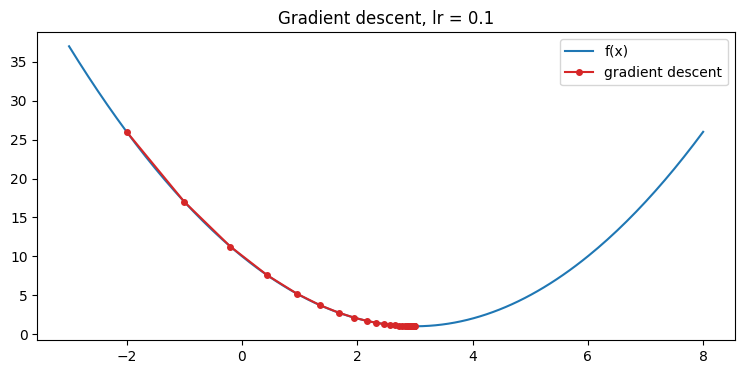

In [43]:
def f(x):
    return (x - 3) ** 2 + 1

x = torch.tensor(-2.0, requires_grad=True)
lr = 0.1
trajectory = [x.item()]

for step in range(30):
    loss = f(x)
    loss.backward()              # computes f'(x) -> x.grad
    with torch.no_grad():        # the update must not end up in the graph
        x -= lr * x.grad
    x.grad.zero_()               # reset the gradient for the next step
    trajectory.append(x.item())

print(f"Minimum found: x = {x.item():.4f}  (expected 3)")

xs = torch.linspace(-3, 8, 200)
traj = torch.tensor(trajectory)
plt.figure(figsize=(9, 4))
plt.plot(xs, f(xs), label="f(x)")
plt.plot(traj, f(traj), "o-", color="tab:red", ms=4, label="gradient descent")
plt.legend()
plt.title(f"Gradient descent, lr = {lr}")
plt.show()

🧪 **Let's change the learning rate.** What happens with `lr = 0.01`? And with `lr = 0.9`? And with `lr = 1.05`?

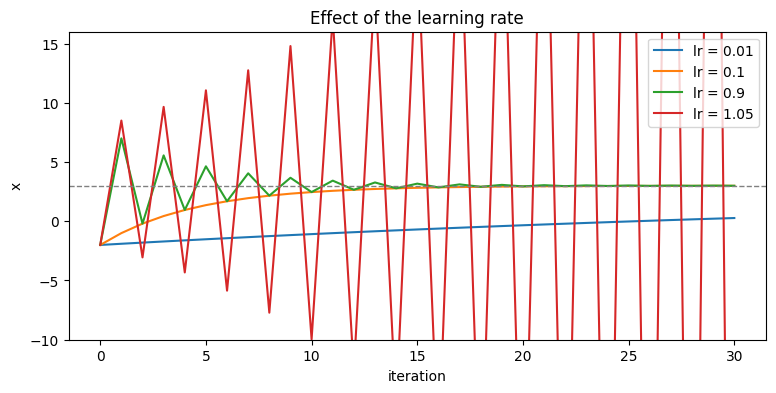

In [44]:
plt.figure(figsize=(9, 4))
for lr in [0.01, 0.1, 0.9, 1.05]:
    x = torch.tensor(-2.0, requires_grad=True)
    values = [x.item()]
    for step in range(30):
        f(x).backward()
        with torch.no_grad():
            x -= lr * x.grad
        x.grad.zero_()
        values.append(x.item())
    plt.plot(values, label=f"lr = {lr}")

plt.axhline(3, color="gray", ls="--", lw=1)
plt.ylim(-10, 16)
plt.xlabel("iteration")
plt.ylabel("x")
plt.legend()
plt.title("Effect of the learning rate")
plt.show()

### 14.1 Bonus: gradient descent in 2D

Same idea, but with two variables: $f(x, y) = x^2 + 5y^2$. The gradient is now a vector
$\nabla f = (2x,\ 10y)$, and we compute it with autograd by keeping the parameters in a single tensor.

Final point: tensor([-3.7431e-03,  2.1990e-28])


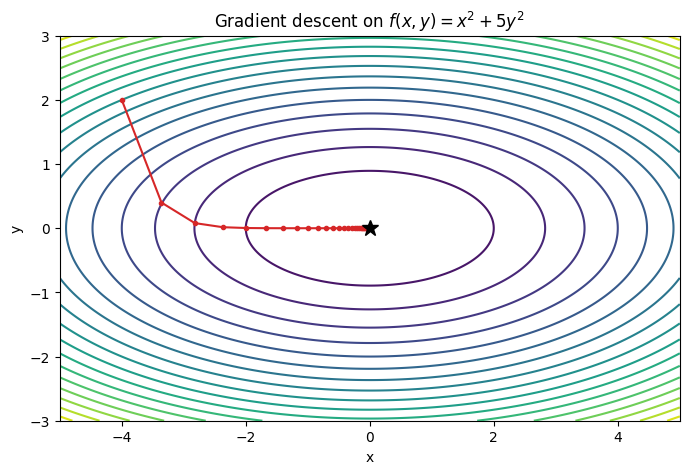

In [45]:
def f2(p):
    return p[0] ** 2 + 5 * p[1] ** 2

p = torch.tensor([-4.0, 2.0], requires_grad=True)
lr = 0.08
path = [p.detach().clone()]

for step in range(40):
    f2(p).backward()
    with torch.no_grad():
        p -= lr * p.grad
    p.grad.zero_()
    path.append(p.detach().clone())

path = torch.stack(path)
print("Final point:", p.detach())

gx, gy = torch.meshgrid(torch.linspace(-5, 5, 200), torch.linspace(-3, 3, 200), indexing="xy")
plt.figure(figsize=(8, 5))
plt.contour(gx, gy, gx**2 + 5 * gy**2, levels=20, cmap="viridis")
plt.plot(path[:, 0], path[:, 1], "o-", color="tab:red", ms=3)
plt.plot(0, 0, "k*", ms=12)
plt.title(r"Gradient descent on $f(x,y) = x^2 + 5y^2$")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

This is, in miniature, **exactly** what training a neural network does: instead of $(x, y)$
there are millions of weights, instead of $f$ there is the loss on the data, and instead of our manual update
we will use an optimizer from `torch.optim` (SGD, Adam, ...).

---
## 15. Exercises

1. **Tensors.** Create a `(4, 6)` tensor with the numbers from 0 to 23. Extract the even columns, then compute
   the mean of each row. What is the shape of the result? And with `keepdim=True`?
2. **Broadcasting.** Given a batch `X` of shape `(100, 3)`, *standardize* each column (subtract the column mean
   and divide by the column standard deviation) **without** using `for` loops.
3. **Derivatives.** Use autograd to compute the derivative of $f(x) = \ln(1 + x^2)$ on the interval $[-3, 3]$ and
   compare it with the analytic derivative $\frac{2x}{1+x^2}$ (plot + `torch.allclose`).
4. **Partial derivatives.** Compute the gradient of $f(x, y, z) = xyz + \sin(x) e^{y}$ at the point $(1, 0, 2)$
   and check it by hand.
5. **Gradient descent.** Find the minimum of the Rosenbrock function
   $f(x, y) = (1 - x)^2 + 100\,(y - x^2)^2$ starting from $(-1, 1)$. Which learning rate works?
   How many iterations are needed? (The minimum is at $(1, 1)$.)